# ReaderAdapt-Liver - reproducible evaluation

This notebook re-computes every number of the evaluation from a finished run directory
(`outputs/<run>/`, produced by `python -m radagent all --config ...`). It covers:

| Section | Guidance step | Question |
|---|---|---|
| 1 | Data | What was evaluated, with which patient-level split? |
| 2 | Step 1 | How good are segmentation and measurement? |
| 3 | Step 2 | Is the case-level confidence calibrated (Brier, ECE, reliability)? |
| 4 | Step 2/4 | Does uncertainty identify AI errors (selective prediction)? |
| 5 | Step 3 | Does the triage order surface tumour cases first? |
| 6 | Step 4/5 | Universal vs reader-specific vs deferral policies with simulated readers (RQ1-RQ3) |
| 7 | Agent | What did the agent actually do? |

> **Research prototype.** Simulated readers show that the method behaves as designed; they are *not*
> evidence of clinical benefit or of reading-time savings.

Set `RUN` below to the run you want to evaluate (the committed outputs were produced with
`configs/demo.yaml`: synthetic phantoms + the CPU voxel-GBM segmenter).

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from radagent.store import RunStore, load_json
from radagent.config import load_config
from radagent import plots
from radagent.experiments import run_reader_experiment, POLICY_LABELS, benefit_by_reader

RUN = ROOT / "outputs" / "demo"          # <- change to outputs/lits_vitunetr after the LiTS run
store = RunStore(RUN)
cfg = load_config(RUN / "config_used.yaml")
records = store.records()
test = [r for r in records if r["split"] == "test"]
calib = [r for r in records if r["split"] == "calib"]
pd.set_option("display.precision", 3)
print(f"run: {RUN.name} | source: {cfg['data']['source']} | segmenter: {cfg['segmenter']['backend']} | "
      f"records: {len(records)} (calib {len(calib)}, test {len(test)})")

run: demo | source: synthetic | segmenter: voxel_gbm | records: 64 (calib 31, test 33)


## 1. Data and splits
Splits are by patient/case; the calibrator and reader policies never see a test case.

In [2]:
man = store.manifest()
split_counts = man.groupby("split").size().reindex(["train", "val", "calib", "test"])
pos = {s: int(sum(r["reference"]["tumour_present"] for r in records if r["split"] == s)) for s in ("calib", "test")}
pd.DataFrame({"cases": split_counts,
              "with tumour (reference)": pd.Series(pos)}).fillna("-")

,cases,with tumour (reference)
calib,31,13.0
test,33,15.0
train,48,-
val,8,-


## 2. Segmentation and measurement (Step 1)
Dice is computed at the **original resolution** against the reference masks. Volumes use the voxel spacing
from each NIfTI header. One case record looks like this (the structured output of the agent's first read):

In [3]:
ex = next(r for r in test if r["reference"]["tumour_present"])
{k: ex["confidence"][k] for k in ("tumour_probability_raw", "tumour_probability", "uncertainty")} | {
    "case_id": ex["case_id"], "predicted_tumour_volume_ml": ex["measurements"]["predicted_tumour_volume_ml"],
    "n_lesions": ex["measurements"]["n_lesions"], "triage": ex["triage"]["category"], "review_status": ex["review_status"]}

{'tumour_probability_raw': 0.99448, 'tumour_probability': 0.9795, 'uncertainty': 0.14424, 'case_id': 'syn_002', 'predicted_tumour_volume_ml': 18.409, 'n_lesions': 2, 'triage': 'URGENT', 'review_status': 'pending'}

In [4]:
seg = pd.DataFrame([{"case": r["case_id"], "tumour_present": r["reference"]["tumour_present"],
                     "dice_liver": r["reference"]["dice_liver"], "dice_tumour": r["reference"]["dice_tumour"],
                     "pred_tumour_ml": r["measurements"]["predicted_tumour_volume_ml"],
                     "ref_tumour_ml": r["reference"]["tumour_volume_ml"],
                     "pred_liver_ml": r["measurements"]["liver_volume_ml"], "ref_liver_ml": r["reference"]["liver_volume_ml"],
                     "ref_lesions": r["reference"]["n_lesions"], "detected": r["reference"]["lesions_detected"],
                     "fp_lesions": r["reference"]["fp_lesions"]} for r in test])
posc = seg[seg.tumour_present]
summary = pd.Series({
    "liver Dice (mean)": seg.dice_liver.mean(),
    "liver volume error (median |%|)": (100 * (seg.pred_liver_ml - seg.ref_liver_ml).abs() / seg.ref_liver_ml).median(),
    "tumour Dice, cases with tumour (mean)": posc.dice_tumour.mean(),
    "tumour Dice, cases with tumour (median)": posc.dice_tumour.median(),
    "lesion-level sensitivity": posc.detected.sum() / max(1, posc.ref_lesions.sum()),
    "false-positive lesions per case": seg.fp_lesions.mean(),
})
summary.to_frame("test split")

,test split
liver Dice (mean),0.965
liver volume error (median |%|),3.658
"tumour Dice, cases with tumour (mean)",0.378
"tumour Dice, cases with tumour (median)",0.395
lesion-level sensitivity,0.424
false-positive lesions per case,1.636


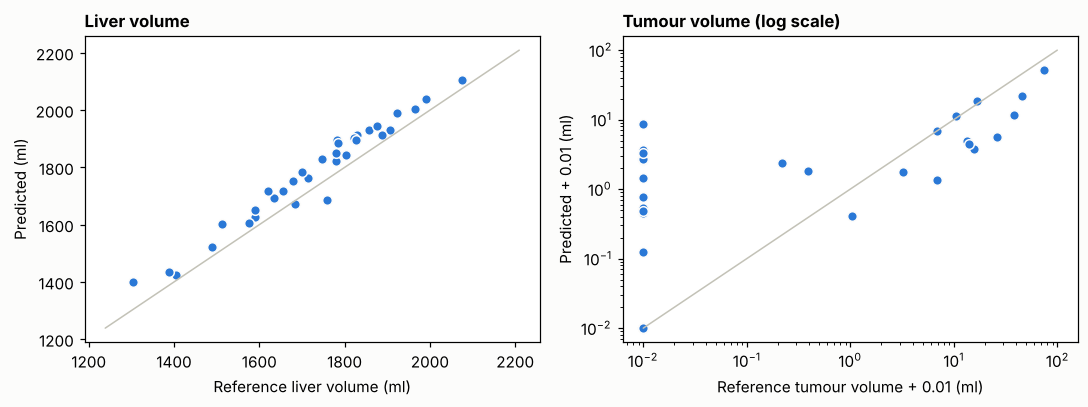

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
plots.style()
axes[0].scatter(seg.ref_liver_ml, seg.pred_liver_ml, color=plots.SERIES[0], edgecolor=plots.SURFACE, s=40)
lim = [seg[["ref_liver_ml", "pred_liver_ml"]].min().min() * 0.95, seg[["ref_liver_ml", "pred_liver_ml"]].max().max() * 1.05]
axes[0].plot(lim, lim, color=plots.AXIS, lw=1); axes[0].set_xlabel("Reference liver volume (ml)"); axes[0].set_ylabel("Predicted (ml)")
axes[0].set_title("Liver volume", loc="left")
axes[1].scatter(seg.ref_tumour_ml + 0.01, seg.pred_tumour_ml + 0.01, color=plots.SERIES[0], edgecolor=plots.SURFACE, s=40)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].plot([0.01, 100], [0.01, 100], color=plots.AXIS, lw=1)
axes[1].set_xlabel("Reference tumour volume + 0.01 (ml)"); axes[1].set_ylabel("Predicted + 0.01 (ml)")
axes[1].set_title("Tumour volume (log scale)", loc="left")
plt.tight_layout()

## 3. Confidence calibration (Step 2)
The raw case score (mean of the top-k smoothed tumour probabilities inside the liver, k = 0.1 ml) is mapped to a
probability on the **calibration split**. Temperature scaling, Platt scaling and no calibration are compared by
5-fold cross-validated NLL on the calibration split only; the winner is refitted on the full calibration split
and evaluated once on the test split. Intervals are 95 % bootstrap intervals over test cases.

In [6]:
cm = load_json(RUN / "calibration" / "calibration_metrics.json")
print("calibrator:", cm["calibrator"]["description"], "| selection:", cm["fit"].get("cv_nll"))
rows = []
for stage in ("before", "after"):
    m = cm["test"][stage]
    rows.append({"stage": "raw score" if stage == "before" else "calibrated", "n": m["n"], "positives": m["n_pos"],
                 "Brier": m["brier"], "Brier 95% CI": f"{m['brier_ci'][0]:.3f}-{m['brier_ci'][1]:.3f}",
                 "ECE": m["ece"], "ECE 95% CI": f"{m['ece_ci'][0]:.3f}-{m['ece_ci'][1]:.3f}",
                 "ECE (equal-mass)": m["ece_adaptive"], "NLL": m["nll"], "AUROC": m["auroc"]})
pd.DataFrame(rows).set_index("stage")

calibrator: Platt scaling (a = 1.005, b = -1.355) | selection: {'identity': 0.7134, 'temperature': 0.6592, 'platt': 0.5726}


,n,positives,Brier,Brier 95% CI,ECE,ECE 95% CI,ECE (equal-mass),NLL,AUROC
stage,,,,,,,,,
raw score,33,15,0.273,0.174-0.380,0.316,0.202-0.467,0.375,0.776,0.859
calibrated,33,15,0.165,0.112-0.229,0.174,0.143-0.335,0.238,0.502,0.859


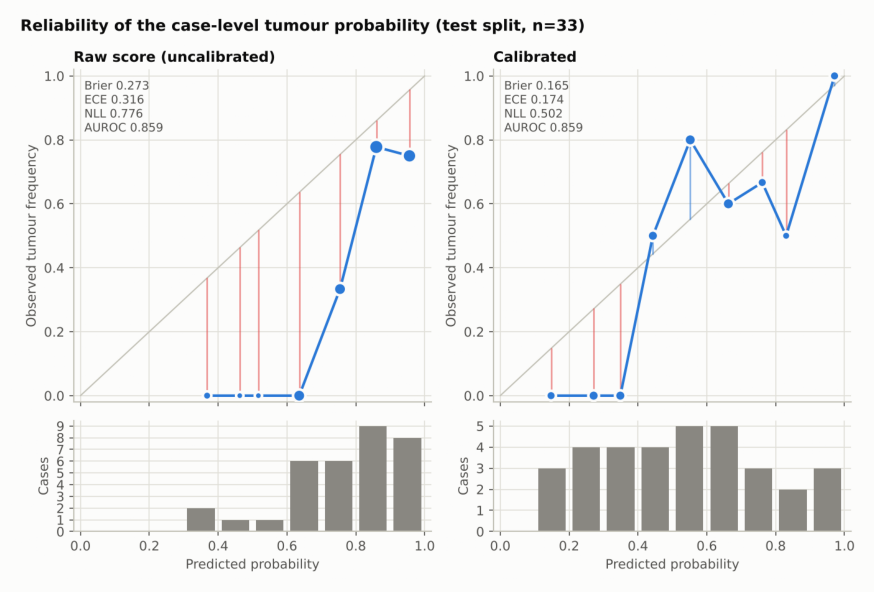

In [7]:
plots.reliability_figure(cm, RUN / "figures" / "calibration_reliability.png")
plt.imshow(plt.imread(RUN / "figures" / "calibration_reliability.png")); plt.axis("off"); plt.gcf().set_size_inches(10, 7)

Calibration changes *what a probability means*, not the ranking: AUROC is unchanged by temperature scaling and
by Platt scaling with a positive slope. With few test cases the ECE interval is wide - the bootstrap interval is
reported so the improvement is not over-read.

## 4. Does uncertainty point at the AI's mistakes? (selective prediction)

In [8]:
from sklearn.metrics import roc_auc_score
t = cfg["triage"]["suggest_threshold"]
p = np.array([r["confidence"]["tumour_probability"] for r in test])
u = np.array([r["confidence"]["uncertainty"] for r in test])
g = np.array([int(r["reference"]["tumour_present"]) for r in test])
ai = (p >= t).astype(int)
err = (ai != g).astype(int)
out = {"AI-alone accuracy": (ai == g).mean(), "sensitivity": ai[g == 1].mean(), "specificity": 1 - ai[g == 0].mean(),
       "AUROC of uncertainty for AI error": roc_auc_score(err, u) if 0 < err.sum() < len(err) else np.nan,
       "error rate, most certain 50%": err[np.argsort(u)[: len(u) // 2]].mean(),
       "error rate, least certain 50%": err[np.argsort(u)[len(u) // 2:]].mean()}
pd.Series(out).to_frame("test split")

,test split
AI-alone accuracy,0.788
sensitivity,0.867
specificity,0.722
AUROC of uncertainty for AI error,0.681
"error rate, most certain 50%",0.125
"error rate, least certain 50%",0.294


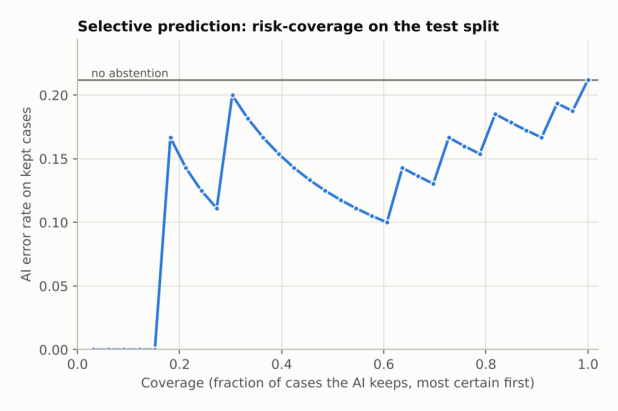

In [9]:
plots.risk_coverage_figure(records, RUN / "figures" / "risk_coverage.png", t)
plt.imshow(plt.imread(RUN / "figures" / "risk_coverage.png")); plt.axis("off"); plt.gcf().set_size_inches(7, 4.6)

## 5. Worklist triage (Step 3)

In [10]:
pr = np.array([r["triage"]["priority"] for r in test])
order = np.argsort(-pr)
k = max(1, len(test) // 4)
cats = pd.Series([r["triage"]["category"] for r in test]).value_counts()
print("triage categories on the test worklist:", cats.to_dict())
pd.Series({"tumour prevalence": g.mean(), f"tumour rate in the top {k} cases": g[order[:k]].mean(),
           f"tumour rate in the bottom {k} cases": g[order[-k:]].mean()}).to_frame("test split")

triage categories on the test worklist: {'SUSPICIOUS': 15, 'UNCERTAIN': 11, 'LIKELY NORMAL': 4, 'URGENT': 3}


,test split
tumour prevalence,0.455
tumour rate in the top 8 cases,0.875
tumour rate in the bottom 8 cases,0.000


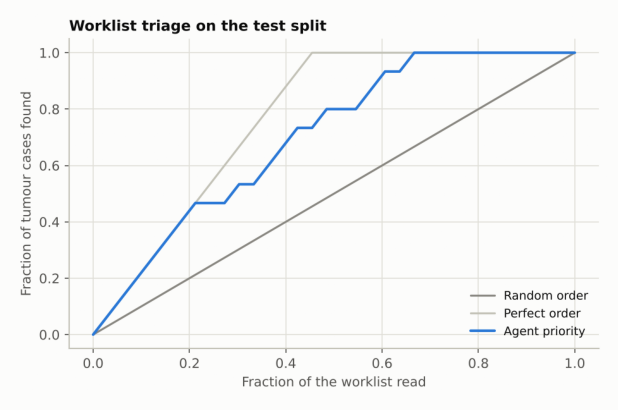

In [11]:
plots.triage_lift_figure(records, RUN / "figures" / "triage_lift.png")
plt.imshow(plt.imread(RUN / "figures" / "triage_lift.png")); plt.axis("off"); plt.gcf().set_size_inches(7, 4.6)

## 6. Reader adaptation and deferral (Steps 4-5)
Re-run the controlled experiment here (deterministic seeds - it reproduces `experiments/*.csv`).

* **Burn-in:** each simulated reader reads the calibration cases with the universal policy (sequential protocol).
* **Fit:** reader-specific threshold / deferral from that reader's feedback (trust curve + lapse rate); a pooled
  deferral rule for `Universal + deferral`.
* **Evaluate:** all policies on the same test cases with the same random draws.
Correctness always comes from the reference annotation.

In [12]:
exp = run_reader_experiment(records, cfg, verbose=False)
s = exp["summary"].copy()
s["policy"] = s["policy"].map(POLICY_LABELS)
cols = ["reader", "policy", "accuracy", "sensitivity", "specificity", "weighted_error", "harmful_acceptance_rate",
        "over_reliance", "deferral_rate", "actions_per_case", "threshold", "personalised_frac"]
s[cols]

,reader,policy,accuracy,sensitivity,specificity,weighted_error,harmful_acceptance_rate,over_reliance,deferral_rate,actions_per_case,threshold,personalised_frac
0,reader_a,Reader alone (no AI),0.828,0.811,0.843,0.258,0.000,NaN,1.000,4.000,0.500,0.000
1,reader_a,Universal threshold,0.803,0.856,0.759,0.263,0.156,0.733,0.000,1.243,0.500,0.000
2,reader_a,Universal + deferral,0.826,0.836,0.819,0.248,0.044,0.880,0.666,3.068,0.500,0.867
3,reader_a,Reader-specific threshold,0.797,0.864,0.741,0.265,0.160,0.688,0.000,1.274,0.467,0.133
4,reader_a,Reader-specific + deferral,0.811,0.847,0.781,0.259,0.105,0.817,0.319,2.115,0.523,0.433
5,reader_b,Reader alone (no AI),0.918,0.871,0.957,0.140,0.000,NaN,1.000,4.000,0.500,0.000
6,reader_b,Universal threshold,0.896,0.871,0.917,0.163,0.056,0.262,0.000,1.781,0.500,0.000
7,reader_b,Universal + deferral,0.909,0.876,0.937,0.147,0.018,0.411,0.666,3.246,0.500,0.867
8,reader_b,Reader-specific threshold,0.889,0.878,0.898,0.167,0.060,0.163,0.000,1.968,0.283,0.833
9,reader_b,Reader-specific + deferral,0.896,0.878,0.911,0.160,0.041,0.295,0.328,2.625,0.380,0.900


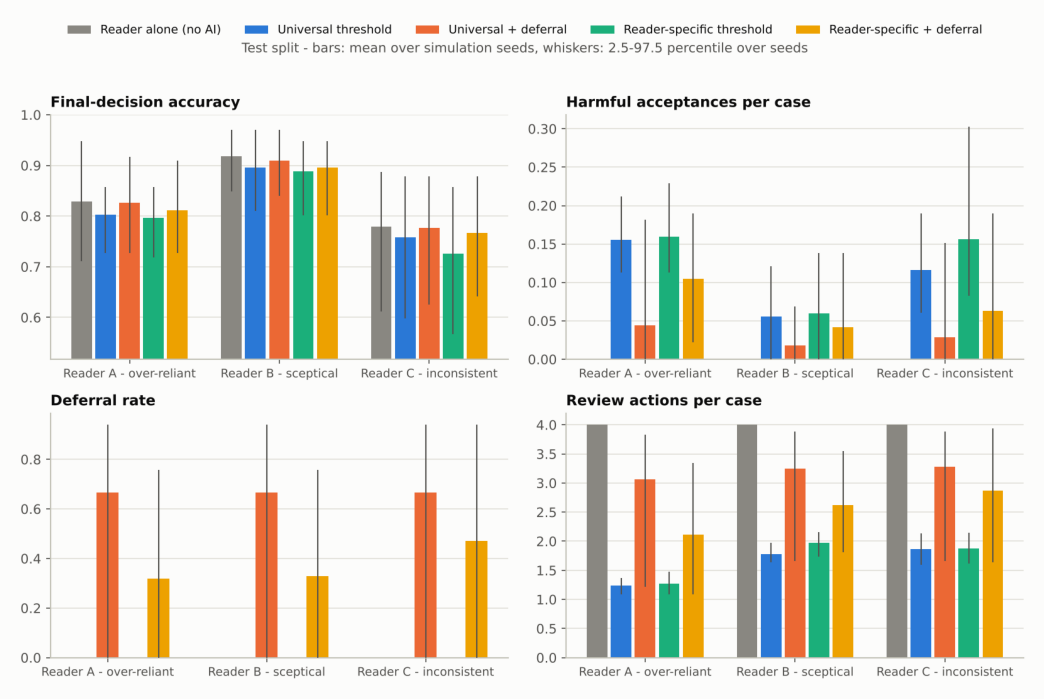

In [13]:
plots.policy_comparison_figure(exp["summary"], cfg, RUN / "figures" / "policy_comparison.png")
plt.imshow(plt.imread(RUN / "figures" / "policy_comparison.png")); plt.axis("off"); plt.gcf().set_size_inches(12, 8)

### RQ1 - Does per-reader adaptation reduce the variation in benefit across readers?

In [14]:
b = exp["benefit_spread"].copy(); b["policy"] = b["policy"].map(POLICY_LABELS); b

,policy,mean_benefit,min_benefit,max_benefit,spread_max_minus_min,std_across_readers
0,Universal threshold,-0.023,-0.025,-0.022,0.003,0.001
1,Universal + deferral,-0.005,-0.009,-0.002,0.007,0.003
2,Reader-specific threshold,-0.038,-0.055,-0.029,0.025,0.011
3,Reader-specific + deferral,-0.018,-0.022,-0.013,0.009,0.004


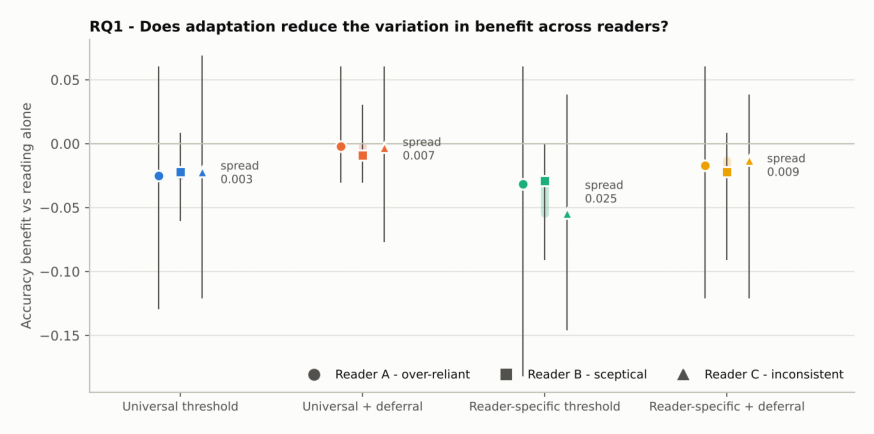

In [15]:
plots.benefit_figure(exp["results"], cfg, RUN / "figures" / "benefit_by_reader.png")
plt.imshow(plt.imread(RUN / "figures" / "benefit_by_reader.png")); plt.axis("off"); plt.gcf().set_size_inches(10, 5)

### RQ2 - Does learning to defer reduce the harm caused by incorrect suggestions?

In [16]:
r = exp["summary"]
piv = r.pivot_table(index="reader", columns="policy", values="harmful_acceptance_rate", observed=False)
piv = piv[[c for c in ["universal", "universal_defer", "reader_threshold", "reader_threshold_defer"] if c in piv]]
piv.columns = [POLICY_LABELS[c] for c in piv.columns]
piv.round(4)

,Universal threshold,Universal + deferral,Reader-specific threshold,Reader-specific + deferral
reader,,,,
reader_a,0.156,0.044,0.160,0.105
reader_b,0.056,0.018,0.060,0.041
reader_c,0.116,0.028,0.157,0.063


### RQ3 - How much feedback is needed, and is the learned policy stable?

In [17]:
lc = exp["learning_curve"]
tab = lc.groupby(["reader", "n_feedback"]).agg(weighted_error=("weighted_error", "mean"),
                                              threshold=("threshold", "mean"),
                                              threshold_sd=("threshold", "std"),
                                              personalised=("personalised", "mean")).round(3)
tab.unstack(0)

weighted_error                    ... personalised                  
reader           reader_a reader_b reader_c  ...     reader_a reader_b reader_c
n_feedback                                   ...                               
0                   0.263    0.163    0.335  ...        0.000    0.000    0.000
5                   0.263    0.163    0.335  ...        0.000    0.000    0.000
10                  0.271    0.157    0.338  ...        0.500    0.633    0.567
15                  0.265    0.156    0.346  ...        0.500    0.567    0.467
20                  0.269    0.157    0.329  ...        0.467    0.700    0.500
25                  0.260    0.154    0.332  ...        0.500    0.733    0.500
31                  0.259    0.160    0.334  ...        0.433    0.900    0.567

[7 rows x 12 columns]

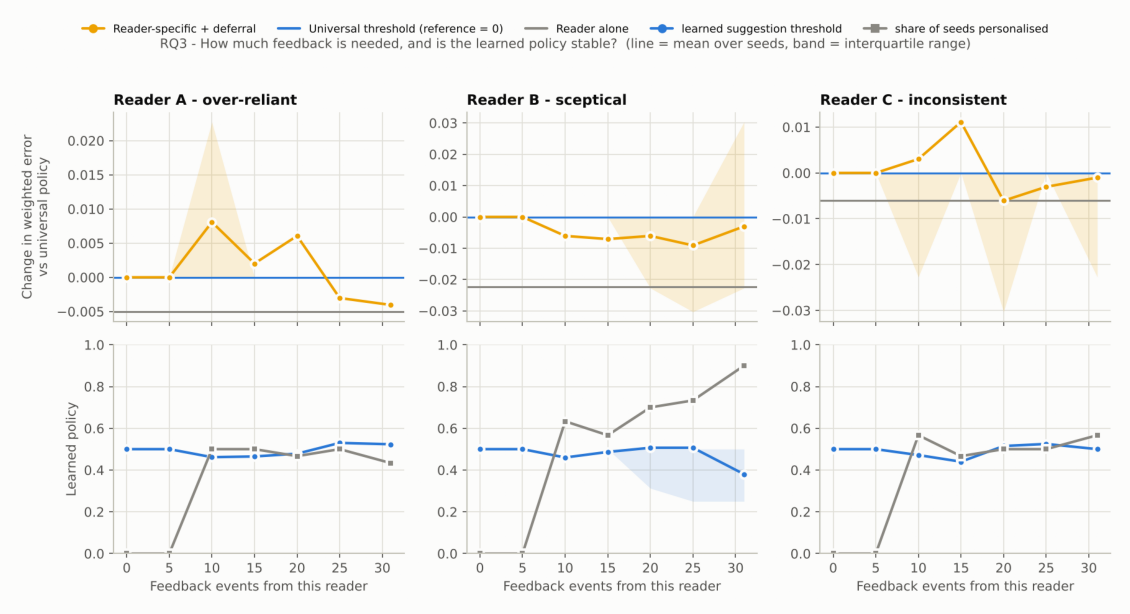

In [18]:
plots.learning_curve_figure(lc, exp["results"], cfg, RUN / "figures" / "learning_curve.png")
plt.imshow(plt.imread(RUN / "figures" / "learning_curve.png")); plt.axis("off"); plt.gcf().set_size_inches(13, 7)

## 7. What did the agent do?
Every first read is a traced plan of tool calls with preconditions enforced by the runner.

In [19]:
steps = []
for f in sorted((RUN / "traces").glob("*.json")):
    tr = json.loads(f.read_text())
    for s_ in tr["steps"]:
        steps.append({"case": tr["case_id"], "planner": tr["planner"], "tool": s_["tool"], "ms": s_.get("duration_ms", 0),
                      "override": bool(s_.get("guardrail"))})
steps = pd.DataFrame(steps)
print(f"{steps.case.nunique()} traces, planner(s): {steps.planner.unique().tolist()}, guardrail overrides: {int(steps.override.sum())}")
steps.groupby("tool", sort=False).agg(calls=("ms", "size"), median_ms=("ms", "median")).round(1)

64 traces, planner(s): ['rule'], guardrail overrides: 0


,calls,median_ms
tool,,
load_study,64,0.2
segment_liver_tumour,64,0.1
measure_findings,64,0.1
quality_check,64,0.0
estimate_confidence,64,0.2
triage_case,64,0.0
draft_report,64,0.5
finish,64,0.0


## Limitations
* **Synthetic demo.** The committed run uses procedurally generated phantoms and a classical CPU segmenter so that
  everything runs without a GPU; its absolute numbers say nothing about real CT. Re-run with
  `configs/lits_vitunetr.yaml` for LiTS results.
* **LiTS case-level imbalance.** Most LiTS volumes contain tumour, so case-level specificity and calibration of the
  negative class rest on few cases; report intervals, and consider `confidence.target_min_tumour_ml` for an
  "actionable burden" definition.
* **Simulated readers** follow a parametric behaviour model (own read -> trust curve -> lapses). Real readers will
  differ - the next step is the pilot with mentor radiologists.
* **Small calibration/burn-in sets** (25-35 cases) make learned thresholds noisy; the policy therefore only
  personalises when the expected improvement clears a margin, and the learning curve shows how this stabilises.